# WQF7009 Assignment 2: XAI on brain MRI data

## Imports and Setup

In [24]:
import os
import shutil
import urllib.request
import zipfile
import hashlib
import copy
import platform
import torch
import torch.nn as nn
import torchvision
import torchvision.models as models
import torchvision.transforms as transforms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.optim as optim
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Set device
device = torch.device("mps" if torch.backends.mps.is_available()
                      else "cuda:0" if torch.cuda.is_available() else "cpu")
print(device, "Python", platform.python_version(), "PyTorch", torch.__version__, "torchvision", torchvision.__version__)

SEED = 26062857
torch.manual_seed(SEED)
np.random.seed(SEED)
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

cuda:0 Python 3.12.10 PyTorch 2.15.0+cu132 torchvision 0.29.2+cu132


## Task 1: Dataset download

### 1.1 Download record

In [25]:
# Download dataset
COMMIT = "3ea9f4eae54c67e5bddbf6f7a73582967a5f5f79"
URL = f"https://github.com/SartajBhuvaji/Brain-Tumor-Classification-DataSet/archive/{COMMIT}.zip"
ZIP_PATH = "data/dataset.zip"
if not os.path.exists("data/brain_mri"):
    urllib.request.urlretrieve(URL, ZIP_PATH)
    print("Downloaded:", URL)
else:
    print("Dataset already downloaded")

Downloaded: https://github.com/SartajBhuvaji/Brain-Tumor-Classification-DataSet/archive/3ea9f4eae54c67e5bddbf6f7a73582967a5f5f79.zip


## Task 2: Folder structure and loading

### 2.1 Folder mapping

In [26]:
# Extract Training and Testing into data/brain_mri/training and testing
if not os.path.exists("data/brain_mri"):
    with zipfile.ZipFile(ZIP_PATH) as z:
        print("Archive commit:", z.comment.decode())
        for member in z.infolist():
            parts = member.filename.split("/")
            if len(parts) > 2 and parts[1] in ("Training", "Testing") and not member.is_dir():
                target = os.path.join("data", "brain_mri", parts[1].lower(), *parts[2:])
                os.makedirs(os.path.dirname(target), exist_ok=True)
                with z.open(member) as f, open(target, "wb") as out:
                    shutil.copyfileobj(f, out)
    os.remove(ZIP_PATH)
print(os.listdir("data"), os.listdir("data/brain_mri"))

Archive commit: 3ea9f4eae54c67e5bddbf6f7a73582967a5f5f79
['brain_mri'] ['testing', 'training']


### 2.2 Loading and class labels

In [27]:
# Load data
TRAIN_ROOT = "data/brain_mri/training"
TEST_ROOT = "data/brain_mri/testing"
train_dataset = torchvision.datasets.ImageFolder(root=TRAIN_ROOT)
test_dataset = torchvision.datasets.ImageFolder(root=TEST_ROOT)

# Image counts, class mapping and dataset inventory
print("Train:", len(train_dataset), train_dataset.class_to_idx)
print("Test:", len(test_dataset), test_dataset.class_to_idx)
assert train_dataset.class_to_idx == test_dataset.class_to_idx
inventory = pd.DataFrame({
    "training": np.bincount(train_dataset.targets),
    "testing": np.bincount(test_dataset.targets)}, index=train_dataset.classes)
inventory["total"] = inventory.sum(axis=1)
inventory.loc["Total"] = inventory.sum()
inventory

Train: 2870 {'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor': 2, 'pituitary_tumor': 3}
Test: 394 {'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor': 2, 'pituitary_tumor': 3}


,training,testing,total
glioma_tumor,826,100,926
meningioma_tumor,822,115,937
no_tumor,395,105,500
pituitary_tumor,827,74,901
Total,2870,394,3264


### 2.3 Separation of data

In [28]:
# Exact duplicate check (MD5)
def file_hashes(dataset):
    return [hashlib.md5(open(path, "rb").read()).hexdigest() for path, _ in dataset.samples]

train_hashes = file_hashes(train_dataset)
test_hashes = file_hashes(test_dataset)
print("Duplicates within training:", len(train_hashes) - len(set(train_hashes)))
print("Duplicates within testing:", len(test_hashes) - len(set(test_hashes)))
print("Test images also in training:", sum(h in set(train_hashes) for h in test_hashes))

Duplicates within training: 93
Duplicates within testing: 80
Test images also in training: 88


## Task 3: LRP and one additional XAI method

### 3.1 Prediction model and experimental setup

In [29]:
# Building the model
class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        self.vgg16 = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)

        # Replace output layer according to our problem
        in_feats = self.vgg16.classifier[6].in_features
        self.vgg16.classifier[6] = nn.Linear(in_feats, 4)

    def forward(self, x):
        x = self.vgg16(x)
        return x

model = CNNModel()
model.to(device)

CNNModel(
  (vgg16): VGG(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (6): ReLU(inplace=True)
      (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): ReLU(inplace=True)
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (11): ReLU(inplace=True)
      (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (13): ReLU(inplace=True)
      (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (15): ReLU(inplace=True)
      (16):

In [30]:
# Prepare data for pretrained model
train_dataset = torchvision.datasets.ImageFolder(
        root=TRAIN_ROOT,
        transform=transforms.Compose([
                      transforms.Resize((255,255)),
                      transforms.ToTensor()
        ])
)

test_dataset = torchvision.datasets.ImageFolder(
        root=TEST_ROOT,
        transform=transforms.Compose([
                      transforms.Resize((255,255)),
                      transforms.ToTensor()
        ])
)

# Create data loaders
batch_size = 32
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED)
)
test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [31]:
# Training model
CHECKPOINT = "vgg16_brain_mri.pt"
cross_entropy_loss = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.00001)
epochs = 10

if os.path.exists(CHECKPOINT):
    model.load_state_dict(torch.load(CHECKPOINT, map_location=device))
    print("Loaded", CHECKPOINT)
else:
    model.train()
    for epoch in range(epochs):
        running_loss = 0
        for i, batch in enumerate(train_loader, 0):
            inputs, labels = batch
            inputs = inputs.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            # Labels are automatically one-hot-encoded
            loss = cross_entropy_loss(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(labels)
        print(f"Epoch {epoch+1}: loss {running_loss/len(train_dataset):.4f}")
    torch.save(model.state_dict(), CHECKPOINT)
model.eval()

Epoch 1: loss 0.8264
Epoch 2: loss 0.3478
Epoch 3: loss 0.1915
Epoch 4: loss 0.1149
Epoch 5: loss 0.0631
Epoch 6: loss 0.0433
Epoch 7: loss 0.0267
Epoch 8: loss 0.0152
Epoch 9: loss 0.0108
Epoch 10: loss 0.0043


CNNModel(
  (vgg16): VGG(
    (features): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (6): ReLU(inplace=True)
      (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (8): ReLU(inplace=True)
      (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (11): ReLU(inplace=True)
      (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (13): ReLU(inplace=True)
      (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (15): ReLU(inplace=True)
      (16):

### 3.2 Layer wise Relevance Propagation

In [32]:
# Layerwise relevance propagation for VGG16
# For other CNN architectures this code might become more complex
# Source: https://git.tu-berlin.de/gmontavon/lrp-tutorial
# http://iphome.hhi.de/samek/pdf/MonXAI19.pdf

def new_layer(layer, g):
    """Clone a layer and pass its parameters through the function g."""
    layer = copy.deepcopy(layer)
    try: layer.weight = torch.nn.Parameter(g(layer.weight))
    except AttributeError: pass
    try: layer.bias = torch.nn.Parameter(g(layer.bias))
    except AttributeError: pass
    return layer

def dense_to_conv(layers):
    """ Converts a dense layer to a conv layer """
    newlayers = []
    for i,layer in enumerate(layers):
        if isinstance(layer, nn.Linear):
            newlayer = None
            if i == 0:
                m, n = 512, layer.weight.shape[0]
                newlayer = nn.Conv2d(m,n,7)
                newlayer.weight = nn.Parameter(layer.weight.reshape(n,m,7,7))
            else:
                m,n = layer.weight.shape[1],layer.weight.shape[0]
                newlayer = nn.Conv2d(m,n,1)
                newlayer.weight = nn.Parameter(layer.weight.reshape(n,m,1,1))
            newlayer.bias = nn.Parameter(layer.bias)
            newlayers += [newlayer]
        else:
            newlayers += [layer]
    return newlayers

def get_linear_layer_indices(model):
    offset = len(model.vgg16._modules['features']) + 1
    indices = []
    for i, layer in enumerate(model.vgg16._modules['classifier']):
        if isinstance(layer, nn.Linear):
            indices.append(i)
    indices = [offset + val for val in indices]
    return indices

def apply_lrp_on_vgg16(model, image, target):
    image = torch.unsqueeze(image, 0)
    # >>> Step 1: Extract layers
    layers = list(model.vgg16._modules['features']) \
                + [model.vgg16._modules['avgpool']] \
                + dense_to_conv(list(model.vgg16._modules['classifier']))
    linear_layer_indices = get_linear_layer_indices(model)
    # >>> Step 2: Propagate image through layers and store activations
    n_layers = len(layers)
    activations = [image] + [None] * n_layers # list of activations

    for layer in range(n_layers):
        if layer in linear_layer_indices:
            if layer == 32:
                activations[layer] = activations[layer].reshape((1, 512, 7, 7))
        activation = layers[layer].forward(activations[layer])
        if isinstance(layers[layer], torch.nn.modules.pooling.AdaptiveAvgPool2d):
            activation = torch.flatten(activation, start_dim=1)
        activations[layer+1] = activation

    # >>> Step 3: Keep only the target class output
    one_hot_output = torch.zeros_like(activations[-1])
    one_hot_output[0, target] = activations[-1][0, target].detach()
    activations[-1] = one_hot_output

    # >>> Step 4: Backpropagate relevance scores
    relevances = [None] * n_layers + [activations[-1]]
    # Iterate over the layers in reverse order
    for layer in range(0, n_layers)[::-1]:
        current = layers[layer]
        # Treat max pooling layers as avg pooling
        if isinstance(current, torch.nn.MaxPool2d):
            layers[layer] = torch.nn.AvgPool2d(2)
            current = layers[layer]
        if isinstance(current, torch.nn.Conv2d) or \
           isinstance(current, torch.nn.AvgPool2d) or\
           isinstance(current, torch.nn.Linear):
            activations[layer] = activations[layer].data.requires_grad_(True)

            # Apply variants of LRP depending on the depth
            # see: https://link.springer.com/chapter/10.1007%2F978-3-030-28954-6_10
            # Lower layers, LRP-gamma >> Favor positive contributions (activations)
            if layer <= 16:       rho = lambda p: p + 0.25*p.clamp(min=0); incr = lambda z: z+1e-9
            # Middle layers, LRP-epsilon >> Remove some noise / Only most salient factors survive
            if 17 <= layer <= 30: rho = lambda p: p;                       incr = lambda z: z+1e-9+0.25*((z**2).mean()**.5).data
            # Upper Layers, LRP-0 >> Basic rule
            if layer >= 31:       rho = lambda p: p;                       incr = lambda z: z+1e-9

            # Transform weights of layer and execute forward pass
            z = incr(new_layer(layers[layer],rho).forward(activations[layer]))
            # Element-wise division between relevance of the next layer and z
            s = (relevances[layer+1]/z).data
            # Calculate the gradient and multiply it by the activation
            (z * s).sum().backward()
            c = activations[layer].grad
            # Assign new relevance values
            relevances[layer] = (activations[layer]*c).data
        else:
            relevances[layer] = relevances[layer+1]

    # >>> Potential Step 5: Apply different propagation rule for pixels
    return relevances[0]

### 3.3 Second XAI method (Grad-CAM)

In [33]:
# Grad-CAM (pytorch-grad-cam)
target_layers = [model.vgg16.features[29]]
cam = GradCAM(model=model, target_layers=target_layers)

### 3.4 Model results and case selection

Number of test samples: 394
Accuracy: 0.761
                  precision    recall  f1-score   support

    glioma_tumor      1.000     0.260     0.413       100
meningioma_tumor      0.699     0.991     0.820       115
        no_tumor      0.739     1.000     0.850       105
 pituitary_tumor      0.873     0.743     0.803        74

        accuracy                          0.761       394
       macro avg      0.828     0.749     0.721       394
    weighted avg      0.819     0.761     0.722       394



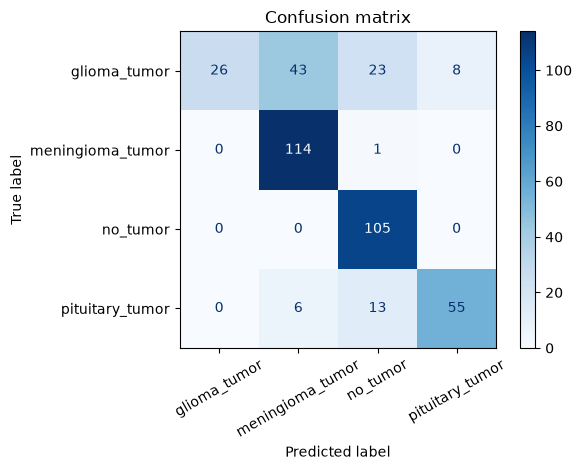

In [34]:
# Predictions for all test images
probs = []
with torch.no_grad():
    for inputs, _ in test_loader:
        probs.append(torch.softmax(model(inputs.to(device)), dim=1).cpu())
probs = torch.cat(probs).numpy()
preds = probs.argmax(1)
labels = np.array(test_dataset.targets)
classes = test_dataset.classes

# Accuracy and per-class report
print("Number of test samples:", len(labels))
print("Accuracy:", round((preds == labels).mean(), 3))
print(classification_report(labels, preds, target_names=classes, digits=3))

# Confusion matrix
cm = confusion_matrix(labels, preds)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(cmap="Blues", xticks_rotation=30)
plt.title("Confusion matrix")
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=200)
plt.show()

### 3.5 Explanation case sheet

File: meningioma_tumor\image(12).jpg
Groundtruth: meningioma_tumor | Prediction: meningioma_tumor | Probability: 0.999748
LRP map: (255, 255) | Grad-CAM map: (255, 255)


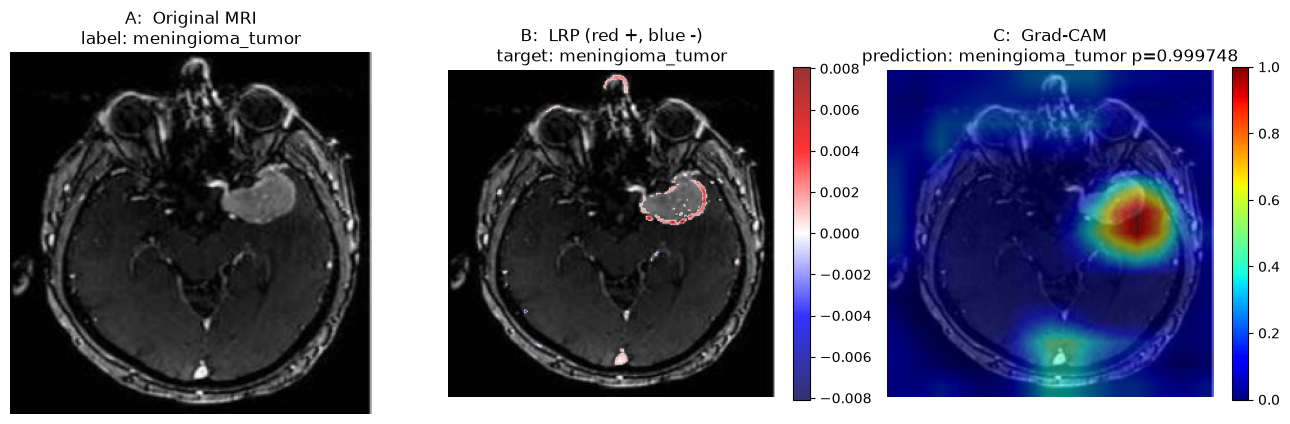

In [35]:
# Explain one test image with LRP and Grad-CAM (same image and target class)
image_id = 111
image, label = test_dataset[image_id]
image = image.to(device)
target = int(preds[image_id])
print("File:", os.path.relpath(test_dataset.samples[image_id][0], TEST_ROOT))
print("Groundtruth:", classes[label], "| Prediction:", classes[target],
      f"| Probability: {probs[image_id, target]:.6f}")

relevance = apply_lrp_on_vgg16(model, image, target).sum(dim=1)[0].cpu().numpy()
grayscale_cam = cam(input_tensor=image.unsqueeze(0), targets=[ClassifierOutputTarget(target)])[0]
mri = image.permute(1, 2, 0).cpu().numpy()
visualization = show_cam_on_image(mri, grayscale_cam, use_rgb=True)
print("LRP map:", relevance.shape, "| Grad-CAM map:", grayscale_cam.shape)

# Plot original MRI, LRP and Grad-CAM next to each other
vmax = np.abs(relevance).max()
fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
# Panel A: original MRI
ax[0].imshow(mri)
ax[0].set_title(f"A:  Original MRI\nlabel: {classes[label]}")

# Panel B: LRP overlay
ax[1].imshow(mri.mean(2), cmap="gray")
lrp_map = np.ma.masked_where(np.abs(relevance) < 0.05 * vmax, relevance)
im1 = ax[1].imshow(lrp_map, cmap="seismic", vmin=-vmax, vmax=vmax, alpha=0.8)
ax[1].set_title(f"B:  LRP (red +, blue -)\ntarget: {classes[target]}")

# Panel C: Grad-CAM overlay
ax[2].imshow(visualization)
ax[2].set_title(f"C:  Grad-CAM\nprediction: {classes[target]} p={probs[image_id, target]:.6f}")
fig.colorbar(im1, ax=ax[1], fraction=0.046)
fig.colorbar(plt.cm.ScalarMappable(cmap="jet", norm=plt.Normalize(0, 1)), ax=ax[2], fraction=0.046)
for a in ax:
    a.axis("off")
plt.tight_layout()
plt.savefig(f"figures/image_{image_id}.png", dpi=200)
plt.show()